## Лабораторная работа №3. Кластеризация
### 1. Введение
**Цель работы:** изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

**Задачи:**
1) Загрузить датасет для задачи кластеризации / классификации. Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2) Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3) Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4) Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5) Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6) Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.

### 2. Описание датасета


Для выполнения лабораторной работы используется датасет Mall Customer Segmentation Data.

Набор данных содержит информацию о 200 покупателях торгового центра и включает пять признаков:

- CustomerID - идентификатор покупателя;
- Gender - пол покупателя;
- Age - возраст;
- Annual Income (k$) - годовой доход в тысячах долларов;
- Spending Score (1-100) - оценка покупательской активности.

Цель анализа - выявить группы покупателей со схожими характеристиками методами кластеризации.

В датасете отсутствует целевая переменная с заранее заданными метками классов. Поэтому задача относится к обучению без учителя.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

df = pd.read_csv("data/Mall_Customers.csv")

print("Размерность:", df.shape)
display(df.head())
display(df.dtypes)


Размерность: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


Датасет содержит 200 наблюдений и 5 признаков. Признаки CustomerID, Age, Annual Income и Spending Score являются числовыми, а Gender - категориальным.

Для оценки качества исходных данных выполняется проверка наличия пропущенных значений и дублирующихся строк.

In [2]:

print("Пропущенные значения:")
display(df.isnull().sum())

print("Количество дубликатов:", df.duplicated().sum())


Пропущенные значения:


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Количество дубликатов: 0


В исходном датасете Mall Customer Segmentation Data пропущенные значения и полные дубликаты отсутствуют. Дополнительная обработка пропусков и удаление повторяющихся наблюдений не требуются.

Для числовых признаков рассчитываются основные описательные статистики: среднее значение, стандартное отклонение, минимум, максимум и квартили.

In [3]:

features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features].copy()

display(X.describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
Age,200.0,38.85,13.97,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,60.56,26.26,15.0,41.50,61.5,78.0,137.0
Spending Score (1-100),200.0,50.20,25.82,1.0,34.75,50.0,73.0,99.0


Возраст покупателей варьируется от 18 до 70 лет, средний возраст составляет 38,85 года, медиана - 36 лет, а стандартное отклонение - 13,97. Это свидетельствует о достаточно широком возрастном диапазоне покупателей.

Годовой доход находится в пределах от 15 до 137 тыс. долларов. Среднее значение составляет 60,56 тыс. долларов, медиана - 61,5 тыс. долларов, стандартное отклонение - 26,26. Близость среднего и медианы указывает на отсутствие выраженной асимметрии в центральной части распределения доходов.

Покупательская активность изменяется от 1 до 99 баллов. Среднее значение составляет 50,20, медиана - 50, а стандартное отклонение - 25,82. Значительный разброс указывает на существенные различия в покупательском поведении клиентов.

Для оценки распределений числовых признаков строятся гистограммы с кривыми плотности. Они позволяют исследовать форму распределений, асимметрию и близость к нормальному распределению.

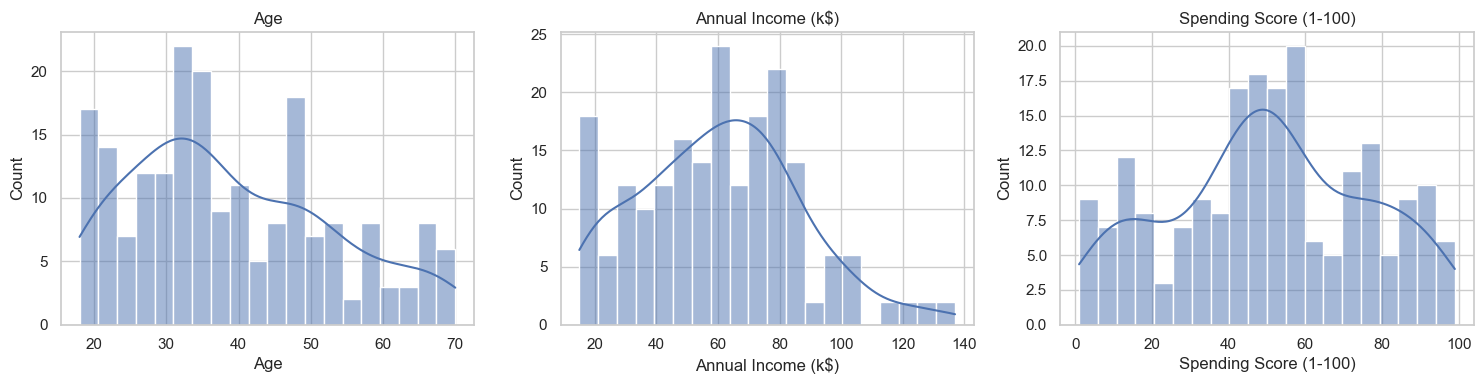

In [4]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, feature in enumerate(features):
    sns.histplot(
        data=X,
        x=feature,
        bins=20,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(feature)

plt.tight_layout()
plt.savefig("figures/02_histograms.png", dpi=300)
plt.show()


Анализ гистограмм показал, что признаки имеют различные распределения.

Возраст (Age) имеет правостороннюю асимметрию. Большинство покупателей находятся в возрасте 25–40 лет, после чего их количество постепенно уменьшается.

Годовой доход (Annual Income) преимущественно сосредоточен в диапазоне 40–80 тыс. долларов. Наблюдается небольшая правосторонняя асимметрия, высокие доходы встречаются значительно реже.

Покупательская активность (Spending Score) характеризуется широким разбросом значений с наибольшей концентрацией в диапазоне 40–60 баллов. Распределение неоднородно.

Распределения признаков не соответствуют идеально нормальному виду.

Для выявления потенциальных выбросов используются диаграммы размаха. Дополнительно применяется межквартильный метод IQR, при котором выбросами считаются значения за пределами интервала от Q1 − 1,5 × IQR до Q3 + 1,5 × IQR.

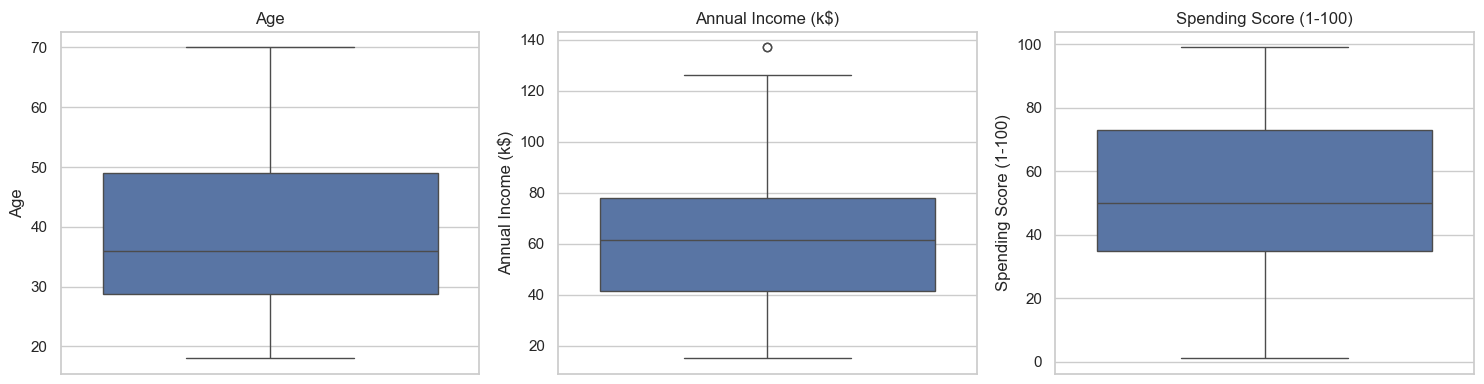

,Количество выбросов
Age,0
Annual Income (k$),2
Spending Score (1-100),0


Объектов с потенциальными выбросами: 2


In [5]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, feature in enumerate(features):
    sns.boxplot(y=X[feature], ax=axes[i])
    axes[i].set_title(feature)

plt.tight_layout()
plt.savefig("figures/02_boxplots.png", dpi=300)
plt.show()

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outlier_mask = (
    (X < Q1 - 1.5 * IQR) |
    (X > Q3 + 1.5 * IQR)
)

display(outlier_mask.sum().to_frame("Количество выбросов"))
print("Объектов с потенциальными выбросами:", outlier_mask.any(axis=1).sum())


Анализ диаграмм размаха и применение метода IQR показали, что в признаках Age и Spending Score выбросы отсутствуют.

В признаке Annual Income обнаружены 2 потенциальных выброса, соответствующих покупателям с наиболее высокими доходами (около 137 тыс. долларов).


Выбросы немногочисленны и не указывают на существенные проблемы с качеством данных.


Для оценки информативности числовых признаков используется метод последовательного исключения признаков (Leave-One-Feature-Out).

Сначала выполняется кластеризация с использованием всех признаков, затем каждый признак поочерёдно исключается, после чего кластеризация повторяется.

Качество разбиения оценивается с помощью коэффициента силуэта (Silhouette Score). Уменьшение коэффициента после исключения признака свидетельствует о его положительном вкладе в качество кластеризации.

Для предварительного анализа используется алгоритм K-means с количеством кластеров k = 5 и параметром n_init=10.

Данный метод позволяет оценить полезность признаков для выбранной модели кластеризации без использования целевой переменной.

,Признак,Silhouette без признака,Изменение качества
2,Spending Score (1-100),0.3958,0.0208
1,Annual Income (k$),0.4475,-0.0309
0,Age,0.5547,-0.1380


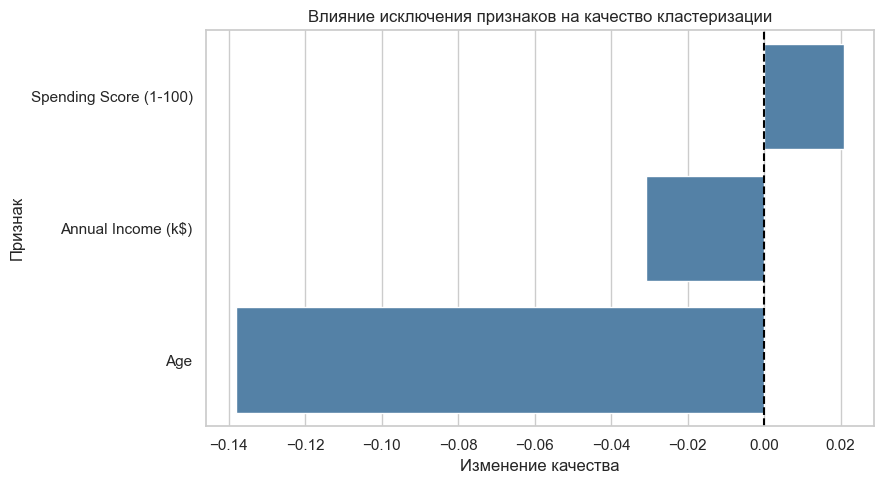

In [6]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features].copy()

def feature_score(columns, k=5):
    data = StandardScaler().fit_transform(X[columns])

    labels = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    ).fit_predict(data)

    return silhouette_score(data, labels)

baseline = feature_score(features)

importance_results = []

for feature in features:
    remaining = [f for f in features if f != feature]
    score = feature_score(remaining)

    importance_results.append({
        "Признак": feature,
        "Silhouette без признака": score,
        "Изменение качества": baseline - score
    })

importance_df = pd.DataFrame(importance_results)
importance_df = importance_df.sort_values(
    "Изменение качества",
    ascending=False
)

display(importance_df.round(4))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Изменение качества",
    y="Признак",
    color="steelblue"
)

plt.axvline(0, color="black", linestyle="--")
plt.title("Влияние исключения признаков на качество кластеризации")
plt.tight_layout()
plt.show()


Наибольший положительный вклад в качество кластеризации вносит Spending Score. При его исключении Silhouette Score уменьшается на 0,0208.

Исключение Annual Income приводит к увеличению Silhouette Score на 0,0309, а исключение Age - на 0,1380. Это указывает на то, что без возрастного признака формируются более компактные и разделённые кластеры по выбранной метрике.

Таким образом, наиболее полезным для рассматриваемого разбиения оказался признак покупательской активности, тогда как возраст сильнее всего снижает коэффициент силуэта при использовании всех трёх признаков.

### 3. Предобработка данных

Для кластеризации используются три числовых признака: Age, Annual Income и Spending Score.

Признак CustomerID исключён, поскольку является идентификатором объекта. Категориальный признак Gender не включается в выбранную числовую модель.

Перед применением алгоритмов выполняется стандартизация с помощью StandardScaler.

Метод выбран из-за чувствительности алгоритмов K-means и иерархической кластеризации к масштабу признаков.

In [11]:

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

scaling_stats = pd.DataFrame({
    "Признак": features,
    "Среднее до": X.mean().values,
    "Ст. отклонение до": X.std(ddof=0).values,
    "Среднее после": X_scaled_df.mean().values,
    "Ст. отклонение после": X_scaled_df.std(ddof=0).values
})

numeric_cols = scaling_stats.select_dtypes(include="number").columns

scaling_stats[numeric_cols] = scaling_stats[numeric_cols].mask(
    scaling_stats[numeric_cols].abs() < 1e-10,
    0
)

display(scaling_stats.round(4))


,Признак,Среднее до,Ст. отклонение до,Среднее после,Ст. отклонение после
0,Age,38.85,13.9340,0.0,1.0
1,Annual Income (k$),60.56,26.1990,0.0,1.0
2,Spending Score (1-100),50.20,25.7589,0.0,1.0


После стандартизации средние значения признаков близки к нулю, а стандартные отклонения равны единице. Таким образом, числовые признаки приведены к сопоставимому масштабу.

Для сравнения масштабов признаков до и после стандартизации строятся диаграммы размаха.

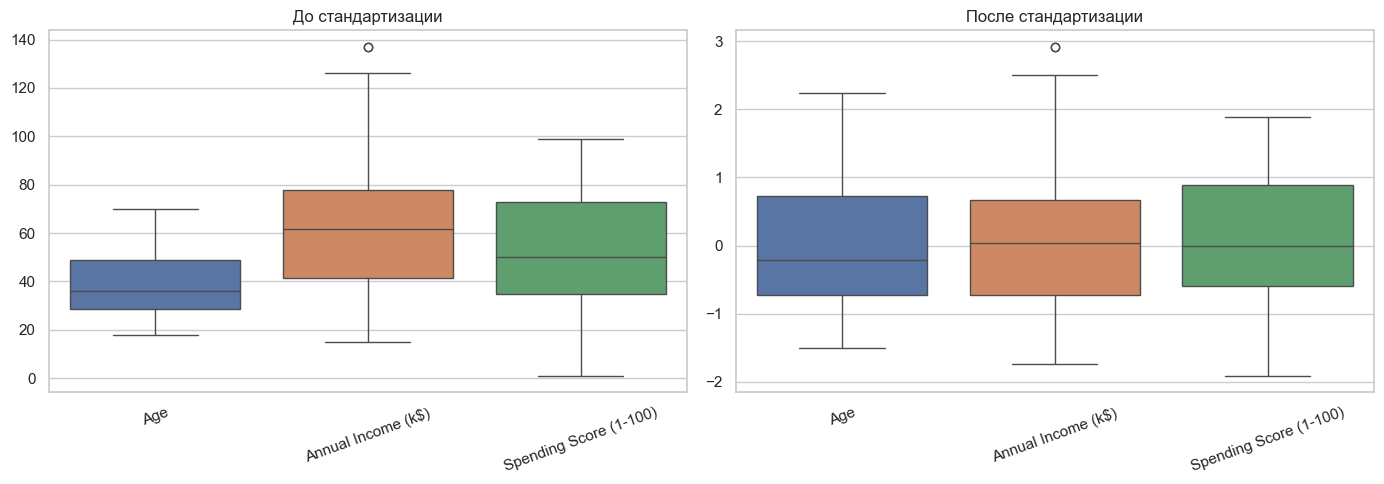

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=X, ax=axes[0])
axes[0].set_title("До стандартизации")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=X_scaled_df, ax=axes[1])
axes[1].set_title("После стандартизации")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("figures/03_scaling.png", dpi=300)
plt.show()


До стандартизации признаки имели разные масштабы и диапазоны значений, что могло приводить к неравномерному влиянию признаков на результаты кластеризации.

После применения StandardScaler значения признаков были приведены к сопоставимому масштабу со средним, равным примерно нулю, и стандартным отклонением, равным единице.

При этом форма распределений сохранилась, включая два потенциальных выброса в признаке Annual Income.

### 4. Ход работы
#### 4.1. Матрица диаграмм рассеивания

Для предварительной оценки кластерной структуры строится матрица диаграмм рассеивания стандартизированных признаков. Она позволяет исследовать взаимное расположение покупателей и предположить количество, форму и плотность возможных кластеров.

Визуальный анализ показал наличие нескольких относительно компактных скоплений покупателей с различной плотностью и частичным перекрытием объектов. Для исследования такой структуры выбраны K-means и иерархическая кластеризация методом Уорда. Оба метода ориентированы на формирование компактных групп, однако могут по-разному распределять объекты при различиях в размерах и плотности кластеров. Поэтому их сравнение позволяет оценить влияние способа формирования групп на результаты кластеризации.

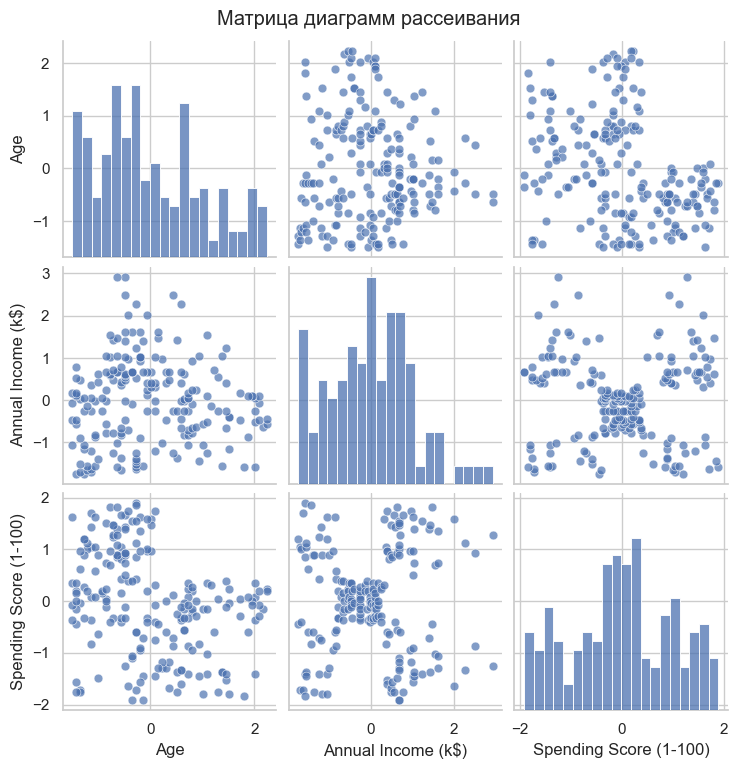

In [12]:

pair_grid = sns.pairplot(
    X_scaled_df,
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 40},
    diag_kws={"bins": 20}
)

pair_grid.fig.suptitle(
    "Матрица диаграмм рассеивания",
    y=1.02
)

plt.show()


Анализ матрицы диаграмм рассеивания показал, что наиболее выраженная групповая структура наблюдается между признаками Annual Income и Spending Score. В этом пространстве можно предположить наличие около пяти скоплений покупателей, различающихся уровнем дохода и покупательской активностью.

В сочетаниях с признаком Age наблюдается более сильное перекрытие объектов, хотя заметны отдельные области повышенной плотности.

Данные имеют предположительную кластерную структуру с группами различной плотности и степени разделимости. Для определения оптимального количества кластеров необходимо применить метод локтя и силуэтный анализ.

#### 4.2. Определение оптимального количества кластеров методом локтя

Метод локтя (Elbow Method) основан на анализе зависимости внутрикластерной суммы квадратов расстояний (Inertia) от количества кластеров.

Оптимальное количество кластеров предполагается в области, после которой дальнейшее увеличение k приводит к менее существенному уменьшению Inertia.

Исследуются значения k от 2 до 10. Для каждого значения используется K-means с параметрами n_init=10 и random_state=42.

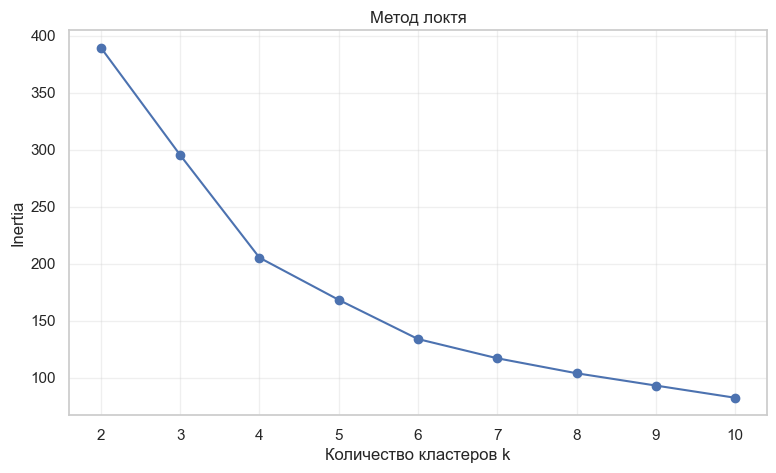

In [13]:

k_values = range(2, 11)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Количество кластеров k")
plt.ylabel("Inertia")
plt.title("Метод локтя")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()


График показывает, что при увеличении количества кластеров с 2 до 4 значение Inertia резко уменьшается примерно с 390 до 205. Это свидетельствует о значительном снижении внутрикластерного разброса.

После k = 4 снижение Inertia становится более плавным, особенно при количестве кластеров больше 6.

По методу локтя наиболее вероятным количеством кластеров является k = 4, хотя точка перегиба выражена не очень чётко.

#### 4.3. Определение количества кластеров с помощью силуэтного анализа

Silhouette Score оценивает компактность и разделимость кластеров.

Значение коэффициента находится в диапазоне от -1 до 1. Чем выше значение, тем лучше объекты соответствуют собственным кластерам относительно соседних кластеров.

Для каждого количества кластеров от 2 до 10 рассчитывается Silhouette Score. Результаты сопоставляются с методом локтя.

,k,Inertia,Silhouette Score
0,2,389.3862,0.3355
1,3,295.2122,0.3578
2,4,205.2251,0.4040
3,5,168.2476,0.4166
4,6,133.8684,0.4284
5,7,117.0116,0.4172
6,8,103.8733,0.4082
7,9,93.0929,0.4177
8,10,82.3852,0.4066


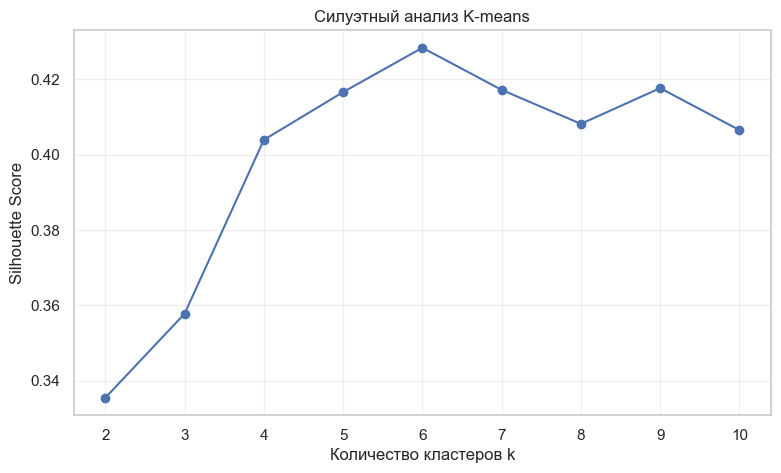

Оптимальное k по Silhouette Score: 6


In [14]:

from sklearn.metrics import silhouette_score

silhouette_results = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    silhouette_results.append(
        silhouette_score(X_scaled, labels)
    )

k_results = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_results
})

display(k_results.round(4))

plt.figure(figsize=(9, 5))
plt.plot(
    list(k_values),
    silhouette_results,
    marker="o"
)
plt.xlabel("Количество кластеров k")
plt.ylabel("Silhouette Score")
plt.title("Силуэтный анализ K-means")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

best_k = int(
    k_results.loc[
        k_results["Silhouette Score"].idxmax(),
        "k"
    ]
)

print("Оптимальное k по Silhouette Score:", best_k)


Силуэтный анализ показал, что максимальное значение Silhouette Score = 0,4284 достигается при k = 6. Это свидетельствует о наиболее качественном разделении объектов на шесть кластеров среди исследованных вариантов.

При k = 5 коэффициент составляет 0,4166, а при k = 4 - 0,4040. Значения указывают на умеренную разделимость кластеров и возможное частичное перекрытие групп.

Таким образом, метод локтя предполагает около четырёх кластеров, тогда как силуэтный анализ показывает наилучший результат при k = 6. Для дальнейшей кластеризации K-means выбирается 6 кластеров, поскольку при этом достигается максимальный Silhouette Score среди проверенных значений k.

#### 4.4. Построение дендрограммы

Для исследования иерархической структуры данных используется агломеративная кластеризация методом Уорда.

Дендрограмма отображает последовательность объединения объектов. Значительные изменения высоты объединений позволяют предположить количество отдельных групп.

Дополнительно для иерархической кластеризации проводится подбор количества кластеров с помощью Silhouette Score.

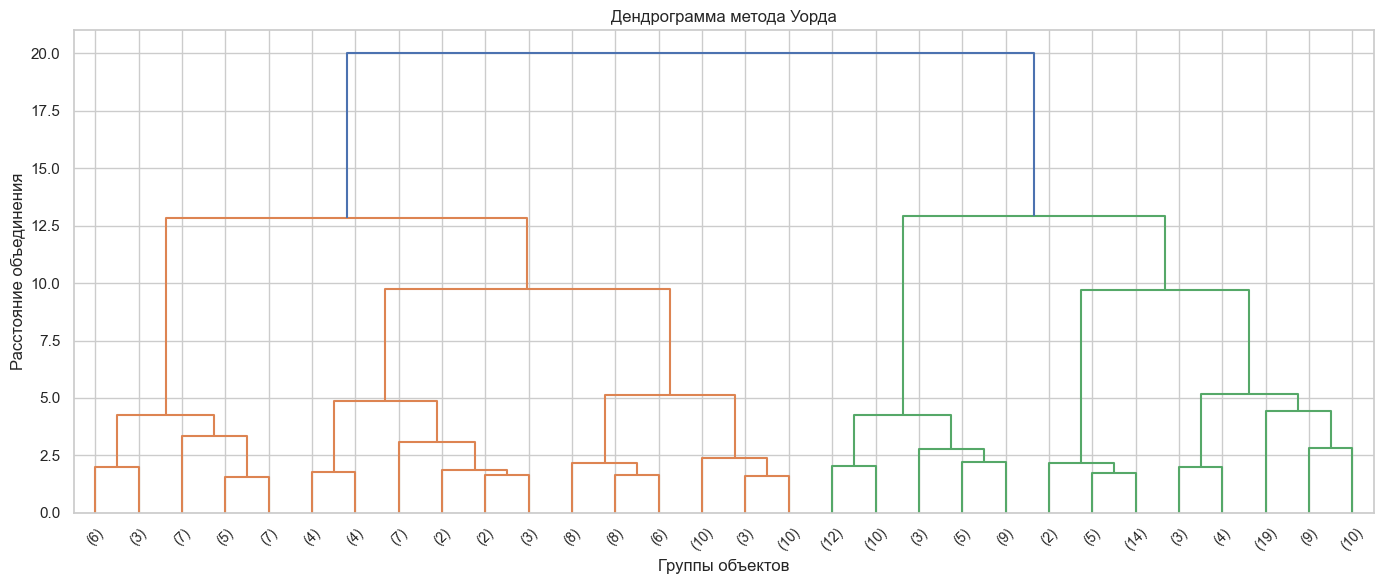

,k,Silhouette Score
0,2,0.3180
1,3,0.3215
2,4,0.3615
3,5,0.3900
4,6,0.4201
5,7,0.3983
6,8,0.3665
7,9,0.3754
8,10,0.3809


Оптимальное k для иерархического метода: 6


In [15]:

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Дендрограмма метода Уорда")
plt.xlabel("Группы объектов")
plt.ylabel("Расстояние объединения")
plt.tight_layout()
plt.show()

hierarchical_scores = []

for k in k_values:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    hierarchical_scores.append(
        silhouette_score(X_scaled, labels)
    )

hierarchical_results = pd.DataFrame({
    "k": list(k_values),
    "Silhouette Score": hierarchical_scores
})

display(hierarchical_results.round(4))

best_k_hierarchical = int(
    hierarchical_results.loc[
        hierarchical_results["Silhouette Score"].idxmax(),
        "k"
    ]
)

print("Оптимальное k для иерархического метода:", best_k_hierarchical)


Дендрограмма метода Уорда показывает наличие нескольких групп объектов, объединяющихся на различных уровнях расстояния. Наиболее крупное объединение происходит на высоте около 20, что свидетельствует о заметных различиях между двумя основными группами покупателей. При более низких уровнях наблюдается дополнительное разделение на меньшие кластеры.

Силуэтный анализ показал, что максимальное значение Silhouette Score = 0,4201 достигается при k = 6. Это указывает на умеренную компактность и разделимость полученных групп.

Таким образом, оптимальным количеством кластеров для иерархического метода по силуэтному анализу является 6, что совпадает с результатом K-means.

#### 4.5. Реализация алгоритмов кластеризации

К стандартизированным данным применяются два метода:

- K-means с параметрами n_init=10 и random_state=42;
- Agglomerative Clustering с методом объединения ward.

Для каждого метода используется количество кластеров, определённое в результате силуэтного анализа. Это позволяет сравнить качество разбиений, оптимизированных отдельно для каждого алгоритма по выбранному критерию.

In [16]:

kmeans = KMeans(
    n_clusters=best_k,
    n_init=10,
    random_state=42
)

hierarchical = AgglomerativeClustering(
    n_clusters=best_k_hierarchical,
    linkage="ward"
)

labels_kmeans = kmeans.fit_predict(X_scaled)
labels_hierarchical = hierarchical.fit_predict(X_scaled)

results_df = df.copy()

results_df["KMeans_Cluster"] = labels_kmeans
results_df["Hierarchical_Cluster"] = labels_hierarchical

print("Количество кластеров K-means:", best_k)
print("Количество кластеров иерархического метода:", best_k_hierarchical)

display(
    results_df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("K-means")
)

display(
    results_df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Иерархический")
)


Количество кластеров K-means: 6
Количество кластеров иерархического метода: 6


,K-means
KMeans_Cluster,
0,45
1,39
2,33
3,39
4,23
5,21


,Иерархический
Hierarchical_Cluster,
0,45
1,45
2,39
3,28
4,22
5,21


Оба алгоритма разделили 200 покупателей на 6 кластеров, что соответствует результатам силуэтного анализа.

Метод K-means сформировал группы численностью от 21 до 45 человек. Наибольший кластер содержит 45 покупателей, наименьший - 21.

При иерархической кластеризации размеры групп варьируются от 21 до 45 человек. Два крупнейших кластера содержат по 45 покупателей.

#### 4.6. Оценка качества кластеризации

Для оценки качества разбиений используются следующие внутренние метрики:

- Silhouette Score - характеризует компактность и разделимость кластеров. Большее значение предпочтительно.
- Calinski-Harabasz Index - оценивает соотношение межкластерного и внутрикластерного разброса. Большее значение предпочтительно.
- Davies-Bouldin Index - оценивает сходство кластеров с учётом их компактности и разделимости. Меньшее значение предпочтительно.

Дополнительно рассчитываются средние расстояния объектов до центров собственных кластеров и расстояния между центрами кластеров.

Поскольку истинные метки классов отсутствуют, внешние метрики относительно эталонной классификации не рассчитываются.

In [17]:

from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score
)
from scipy.spatial.distance import cdist, pdist

def calculate_metrics(data, labels):
    cluster_ids = np.unique(labels)

    centers = np.array([
        data[labels == cluster].mean(axis=0)
        for cluster in cluster_ids
    ])

    center_index = np.searchsorted(cluster_ids, labels)

    distances = cdist(data, centers)

    within = distances[
        np.arange(len(data)),
        center_index
    ].mean()

    between = pdist(centers).mean()

    return {
        "Silhouette Score": silhouette_score(data, labels),
        "Calinski-Harabasz": calinski_harabasz_score(data, labels),
        "Davies-Bouldin": davies_bouldin_score(data, labels),
        "Внутрикластерное расстояние": within,
        "Расстояние между центрами": between
    }

metrics_df = pd.DataFrame({
    "K-means": calculate_metrics(X_scaled, labels_kmeans),
    "Иерархический": calculate_metrics(
        X_scaled,
        labels_hierarchical
    )
}).T

display(metrics_df.round(4))


,Silhouette Score,Calinski-Harabasz,Davies-Bouldin,Внутрикластерное расстояние,Расстояние между центрами
K-means,0.4284,135.1021,0.8254,0.7417,2.3974
Иерархический,0.4201,127.9865,0.8521,0.7578,2.4284


Сравнение метрик показало, что K-means демонстрирует немного лучшие результаты, чем иерархическая кластеризация.

Значение Silhouette Score у K-means составляет 0,4284 против 0,4201, что указывает на несколько лучшую компактность и разделимость кластеров. Индекс Calinski-Harabasz также выше у K-means (135,1021 против 127,9865), а индекс Davies-Bouldin ниже (0,8254 против 0,8521).

Среднее внутрикластерное расстояние у K-means составляет 0,7417 против 0,7578, что подтверждает большую компактность выделенных групп. При этом расстояние между центрами немного выше у иерархического метода (2,4284 против 2,3974).

По большинству рассмотренных метрик K-means обеспечивает более качественное разбиение данных на шесть кластеров.

#### 4.7. Исследование влияния параметров

Для оценки влияния количества кластеров на результаты K-means исследуется зависимость Silhouette Score и Calinski-Harabasz Index от параметра k.

Количество кластеров изменяется от 2 до 10, остальные параметры алгоритма остаются неизменными.

,k,Silhouette,Calinski-Harabasz
0,2,0.3355,107.0956
1,3,0.3578,101.6949
2,4,0.4040,125.6764
3,5,0.4166,125.1009
4,6,0.4284,135.1021
5,7,0.4172,132.7743
6,8,0.4082,131.0062
7,9,0.4177,130.0036
8,10,0.4066,132.6383


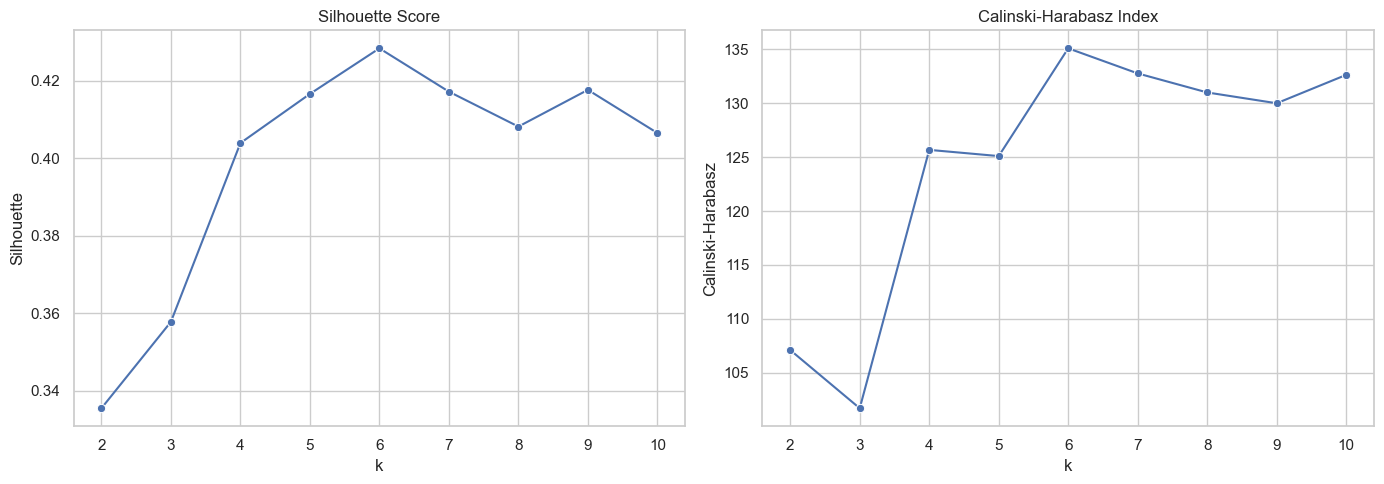

In [18]:

parameter_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    parameter_results.append({
        "k": k,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(
            X_scaled, labels
        )
    })

parameters_df = pd.DataFrame(parameter_results)

display(parameters_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(
    data=parameters_df,
    x="k",
    y="Silhouette",
    marker="o",
    ax=axes[0]
)

sns.lineplot(
    data=parameters_df,
    x="k",
    y="Calinski-Harabasz",
    marker="o",
    ax=axes[1]
)

axes[0].set_title("Silhouette Score")
axes[1].set_title("Calinski-Harabasz Index")

plt.tight_layout()
plt.show()


Изменение количества кластеров существенно влияет на качество кластеризации. При увеличении k от 2 до 6 значение Silhouette Score возрастает с 0,3355 до 0,4284, что свидетельствует об улучшении компактности и разделимости групп.

Максимальные значения обеих метрик достигаются при k = 6: Silhouette Score = 0,4284 и Calinski-Harabasz Index = 135,1021. При дальнейшем увеличении количества кластеров показатели колеблются, но не превышают достигнутых максимумов.

#### 4.8. Исследование устойчивости кластеризации

Для проверки устойчивости K-means выполняются повторные запуски алгоритма с различными значениями random_state.

Для иерархического метода проверяется устойчивость при повторном формировании кластеров на случайных подвыборках.

Сходство разбиений оценивается с помощью Adjusted Rand Index (ARI). Значения, близкие к единице, соответствуют высокой согласованности результатов.

Проверка на подвыборках проводится на общих объектах, присутствующих в обоих сравниваемых разбиениях.

In [19]:

from sklearn.metrics import adjusted_rand_score

kmeans_stability = []

for seed in range(20):
    labels = KMeans(
        n_clusters=best_k,
        n_init=10,
        random_state=seed
    ).fit_predict(X_scaled)

    kmeans_stability.append(
        adjusted_rand_score(labels_kmeans, labels)
    )

rng = np.random.default_rng(42)

hierarchical_stability = []

for i in range(20):
    indices = rng.choice(
        len(X_scaled),
        size=int(len(X_scaled) * 0.8),
        replace=False
    )

    labels = AgglomerativeClustering(
        n_clusters=best_k_hierarchical,
        linkage="ward"
    ).fit_predict(X_scaled[indices])

    hierarchical_stability.append(
        adjusted_rand_score(
            labels_hierarchical[indices],
            labels
        )
    )

stability_df = pd.DataFrame({
    "Метод": ["K-means", "Иерархический"],
    "Среднее ARI": [
        np.mean(kmeans_stability),
        np.mean(hierarchical_stability)
    ],
    "Стандартное отклонение ARI": [
        np.std(kmeans_stability),
        np.std(hierarchical_stability)
    ],
    "Минимальное ARI": [
        np.min(kmeans_stability),
        np.min(hierarchical_stability)
    ]
})

display(stability_df.round(4))


,Метод,Среднее ARI,Стандартное отклонение ARI,Минимальное ARI
0,K-means,0.9894,0.0115,0.9438
1,Иерархический,0.8041,0.0669,0.6120


K-means демонстрирует высокую стабильность результатов при изменении случайной инициализации. Среднее значение ARI составляет 0,9894, стандартное отклонение - 0,0115, а минимальное значение - 0,9438. Это свидетельствует о практически полном совпадении получаемых разбиений.

Для иерархической кластеризации среднее значение ARI составляет 0,8041, стандартное отклонение - 0,0669, минимальное значение - 0,6120. Это указывает на достаточно высокую, но меньшую устойчивость разбиений при изменении состава выборки.

### 5. Визуализация результатов

Для сравнения результатов кластеризации используется метод главных компонент (PCA), позволяющий представить стандартизированные данные в двумерном пространстве.

Для каждого алгоритма строится диаграмма рассеивания с выделением кластеров различными цветами.

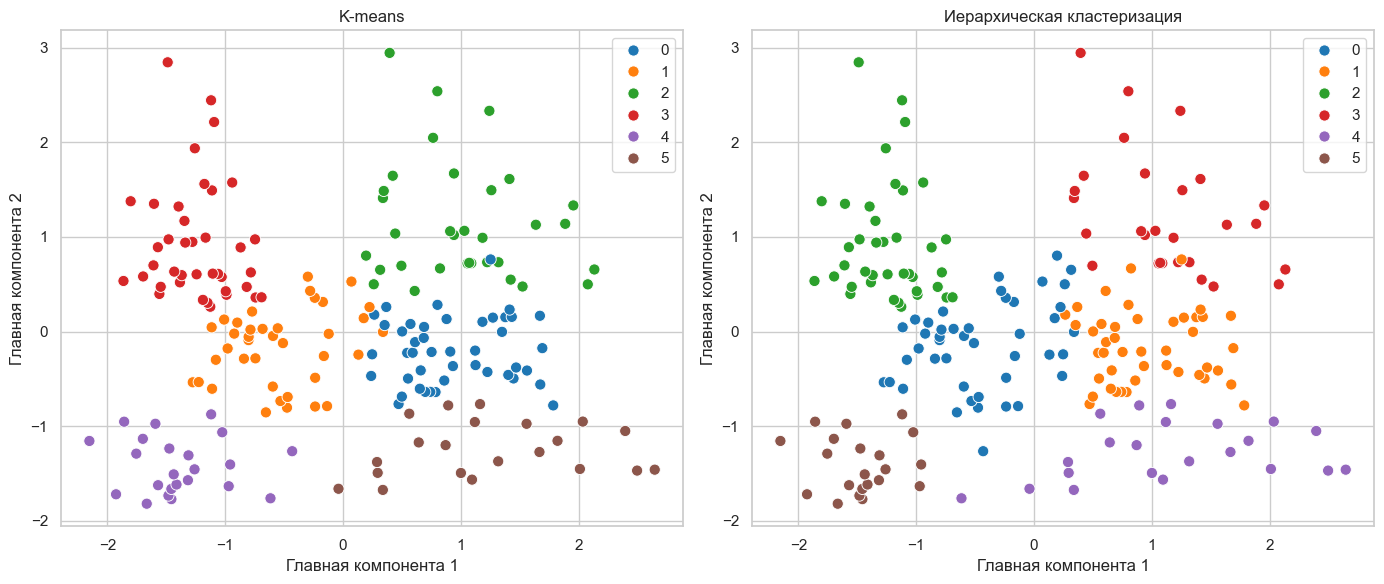

Объяснённая дисперсия: 0.7757


In [20]:

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, labels, title in zip(
    axes,
    [labels_kmeans, labels_hierarchical],
    ["K-means", "Иерархическая кластеризация"]
):
    sns.scatterplot(
        x=X_pca[:, 0],
        y=X_pca[:, 1],
        hue=labels,
        palette="tab10",
        s=65,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Главная компонента 1")
    ax.set_ylabel("Главная компонента 2")

plt.tight_layout()
plt.show()

print(
    "Объяснённая дисперсия:",
    round(pca.explained_variance_ratio_.sum(), 4)
)


Визуализация показала, что оба алгоритма выделили 6 кластеров, имеющих схожую структуру, но различающихся распределением отдельных объектов.

Метод K-means сформировал относительно компактные группы, хотя в центральной области наблюдается частичное перекрытие кластеров. При иерархической кластеризации также выделяются шесть групп, однако некоторые объекты распределены между ними иначе, особенно в центральной части графика.

Первые две главные компоненты PCA объясняют 77,57% общей дисперсии данных, что позволяет достаточно информативно представить результаты кластеризации в двумерном пространстве.

Для содержательной интерпретации кластеров рассчитываются средние значения возраста, годового дохода и покупательской активности внутри каждой группы.

Полученные характеристики позволяют определить особенности выделенных сегментов покупателей.

In [21]:

profile_kmeans = results_df.groupby(
    "KMeans_Cluster"
)[features].agg(["mean", "count"])

profile_hierarchical = results_df.groupby(
    "Hierarchical_Cluster"
)[features].agg(["mean", "count"])

print("K-means:")
display(profile_kmeans.round(2))

print("Иерархическая кластеризация:")
display(profile_hierarchical.round(2))

print("Центры K-means в исходном масштабе:")
display(
    pd.DataFrame(
        scaler.inverse_transform(kmeans.cluster_centers_),
        columns=features
    ).round(2)
)


K-means:


Age       Annual Income (k$)       Spending Score (1-100)  \
                 mean count               mean count                   mean   
KMeans_Cluster                                                                
0               56.33    45              54.27    45                  49.07   
1               26.79    39              57.10    39                  48.13   
2               41.94    33              88.94    33                  16.97   
3               32.69    39              86.54    39                  82.13   
4               25.00    23              25.26    23                  77.61   
5               45.52    21              26.29    21                  19.38   

                      
               count  
KMeans_Cluster        
0                 45  
1                 39  
2                 33  
3                 39  
4                 23  
5                 21

Иерархическая кластеризация:


Age       Annual Income (k$)        \
                       mean count               mean count   
Hierarchical_Cluster                                         
0                     27.38    45              57.51    45   
1                     56.40    45              55.29    45   
2                     32.69    39              86.54    39   
3                     43.89    28              91.29    28   
4                     44.32    22              25.77    22   
5                     24.81    21              25.62    21   

                     Spending Score (1-100)        
                                       mean count  
Hierarchical_Cluster                               
0                                     45.84    45  
1                                     48.36    45  
2                                     82.13    39  
3                                     16.68    28  
4                                     20.27    22  
5                                     80.24    21

Центры K-means в исходном масштабе:


,Age,Annual Income (k$),Spending Score (1-100)
0,56.33,54.27,49.07
1,26.79,57.10,48.13
2,41.94,88.94,16.97
3,32.69,86.54,82.13
4,25.00,25.26,77.61
5,45.52,26.29,19.38


Анализ средних значений признаков показал, что оба алгоритма выделили 6 групп покупателей, различающихся возрастом, доходом и покупательской активностью.

Метод K-means позволил выделить следующие группы:
- Кластер 0 (45 человек) - покупатели старшего возраста (56,33 года) со средним доходом (54,27 тыс. долларов) и умеренной активностью (49,07).
- Кластер 1 (39 человек) - молодые покупатели (26,79 года) со средним доходом (57,10 тыс. долларов) и умеренной активностью (48,13).
- Кластер 2 (33 человека) - покупатели с высоким доходом (88,94 тыс. долларов) и низкой активностью (16,97).
- Кластер 3 (39 человек) - покупатели с высоким доходом (86,54 тыс. долларов) и высокой активностью (82,13).
- Кластер 4 (23 человека) - молодые покупатели (25 лет) с низким доходом (25,26 тыс. долларов) и высокой активностью (77,61).
- Кластер 5 (21 человек) - покупатели среднего возраста (45,52 года) с низким доходом (26,29 тыс. долларов) и низкой активностью (19,38).

Иерархическая кластеризация выделила аналогичные по характеристикам группы, однако их численность и средние значения признаков немного отличаются. Наиболее близкие результаты наблюдаются для покупателей с высоким доходом и высокой активностью, а также для групп с низким доходом.

Для дополнительного сравнения результатов K-means и иерархической кластеризации рассчитывается Adjusted Rand Index.

Метрика определяет степень совпадения разбиений независимо от присвоенных номеров кластеров.

In [22]:

ari_methods = adjusted_rand_score(
    labels_kmeans,
    labels_hierarchical
)

print("ARI между методами:", round(ari_methods, 4))

display(
    pd.crosstab(
        results_df["KMeans_Cluster"],
        results_df["Hierarchical_Cluster"]
    )
)


ARI между методами: 0.8914


Hierarchical_Cluster,0,1,2,3,4,5
KMeans_Cluster,,,,,,
0,2,43,0,0,0,0
1,39,0,0,0,0,0
2,3,2,0,28,0,0
3,0,0,39,0,0,0
4,1,0,0,0,1,21
5,0,0,0,0,21,0


Значение Adjusted Rand Index (ARI) = 0,8914 свидетельствует о высокой степени согласованности результатов K-means и иерархической кластеризации.

Некоторые группы полностью совпадают: например, кластер из 39 покупателей с высокой покупательской активностью и высоким доходом, а также группа из 21 покупателя с низкими доходами и низкой активностью.

Основные различия наблюдаются в распределении покупателей между соседними группами, особенно среди клиентов с высоким доходом и низкой активностью.

### 6. Заключение

В ходе лабораторной работы были изучены и реализованы два метода кластеризации: K-means и иерархическая кластеризация методом Уорда на основе датасета Mall Customer Segmentation Data, содержащего информацию о 200 покупателях торгового центра.

Проведён дескриптивный анализ данных, исследованы распределения признаков и выявлены два потенциальных выброса по годовому доходу, которые были сохранены для дальнейшего анализа. Информационная значимость признаков оценена методом последовательного исключения. Наиболее полезным для выбранного предварительного разбиения оказался признак покупательской активности (Spending Score). Перед кластеризацией выполнена стандартизация числовых признаков с помощью StandardScaler.

Для определения оптимального количества кластеров использовались метод локтя, силуэтный анализ и дендрограмма. Метод локтя позволил предположить наличие около четырёх кластеров, однако максимальное значение Silhouette Score для обоих алгоритмов было достигнуто при k = 6. Поэтому для дальнейшего анализа выбрано шесть кластеров.

Сравнение метрик качества показало небольшое преимущество K-means над иерархической кластеризацией. Значение Silhouette Score составило 0,4284 против 0,4201, Calinski-Harabasz Index - 135,1021 против 127,9865, а Davies-Bouldin Index - 0,8254 против 0,8521. Это свидетельствует о несколько лучшей компактности и разделимости кластеров K-means.

Исследование влияния количества кластеров подтвердило, что при k = 6 достигаются максимальные значения Silhouette Score и Calinski-Harabasz Index среди рассмотренных вариантов. Анализ устойчивости показал высокую стабильность K-means при изменении случайной инициализации (средний ARI = 0,9894). Иерархический метод также продемонстрировал достаточно устойчивые результаты при изменении состава выборки (средний ARI = 0,8041).

На основе анализа центров кластеров были выделены шесть содержательно интерпретируемых групп покупателей: молодые и старшие покупатели со средним доходом и умеренной активностью, покупатели с высоким доходом и низкой или высокой активностью, а также покупатели с низким доходом и низкой или высокой активностью.

Визуализация с использованием PCA показала схожую структуру кластеров для обоих методов. Первые две главные компоненты объясняют 77,57% общей дисперсии данных. Значение Adjusted Rand Index между алгоритмами составило 0,8914, что подтверждает высокую согласованность полученных разбиений.

Оба метода подходят для сегментации покупателей, однако K-means показал несколько лучшие результаты по внутренним метрикам качества.

### 7. Список источников
1) Kaggle. Mall Customer Segmentation Data [Электронный ресурс]. — URL: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

2) Scikit-learn. Clustering — методы кластеризации K-means и Agglomerative Clustering [Электронный ресурс]. — URL: https://scikit-learn.org/stable/modules/clustering.html

3) Scikit-learn. StandardScaler — стандартизация числовых признаков [Электронный ресурс]. — URL: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

### 8. Приложение

In [ ]:
from pathlib import Path
import os

os.chdir(Path(__file__).resolve().parent)


def display(value):
    if hasattr(value, "to_string"):
        print(value.to_string())
    else:
        print(value)



print("\nЗагрузка данных")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")

Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)

df = pd.read_csv("data/Mall_Customers.csv")

if df.empty:
    raise ValueError("Датасет пустой")

print("Количество объектов:", df.shape[0])
print("Количество столбцов:", df.shape[1])
print("Типы столбцов:")
print(df.dtypes.to_string())
print("Целевой переменной с метками классов в датасете нет")

print("Размерность:", df.shape)
display(df.head())
display(df.dtypes)


print("\nПропуски и дубликаты")

print("Пропущенные значения:")
display(df.isnull().sum())

print("Количество дубликатов:", df.duplicated().sum())


print("\nОписательная статистика")

features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features].copy()

if X.isna().any().any():
    raise ValueError("В признаках обнаружены пропуски. Обработайте их перед кластеризацией")

print("Пропущенные значения отсутствуют: обработка не требуется")
print("CustomerID исключён как идентификатор, Gender не включён в числовую модель")

display(X.describe().T.round(2))


print("\nГистограммы")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, feature in enumerate(features):
    sns.histplot(
        data=X,
        x=feature,
        bins=20,
        kde=True,
        color="steelblue",
        ax=axes[i]
    )
    axes[i].set_title(feature)

plt.tight_layout()
plt.savefig("figures/02_histograms.png", dpi=300)
plt.show()


print("\nВыбросы")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, feature in enumerate(features):
    sns.boxplot(y=X[feature], ax=axes[i])
    axes[i].set_title(feature)

plt.tight_layout()
plt.savefig("figures/02_boxplots.png", dpi=300)
plt.show()

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outlier_mask = (
    (X < Q1 - 1.5 * IQR) |
    (X > Q3 + 1.5 * IQR)
)

display(outlier_mask.sum().to_frame("Количество выбросов"))
print("Объектов с потенциальными выбросами:", outlier_mask.any(axis=1).sum())
print("Потенциальные выбросы сохранены: исходные наблюдения не удаляются")


print("\nИнформативность признаков")

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features].copy()

def feature_score(columns, k=5):
    data = StandardScaler().fit_transform(X[columns])

    labels = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    ).fit_predict(data)

    return silhouette_score(data, labels)

baseline = feature_score(features)

importance_results = []

for feature in features:
    remaining = [f for f in features if f != feature]
    score = feature_score(remaining)

    importance_results.append({
        "Признак": feature,
        "Silhouette без признака": score,
        "Изменение качества": baseline - score
    })

importance_df = pd.DataFrame(importance_results)
importance_df = importance_df.sort_values(
    "Изменение качества",
    ascending=False
)

display(importance_df.round(4))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Изменение качества",
    y="Признак",
    color="steelblue"
)

plt.axvline(0, color="black", linestyle="--")
plt.title("Влияние исключения признаков на качество кластеризации")
plt.tight_layout()
plt.savefig("figures/02_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


print("\nСтандартизация")

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

scaling_stats = pd.DataFrame({
    "Признак": features,
    "Среднее до": X.mean().values,
    "Ст. отклонение до": X.std(ddof=0).values,
    "Среднее после": X_scaled_df.mean().values,
    "Ст. отклонение после": X_scaled_df.std(ddof=0).values
})

numeric_cols = scaling_stats.select_dtypes(include="number").columns

scaling_stats[numeric_cols] = scaling_stats[numeric_cols].mask(
    scaling_stats[numeric_cols].abs() < 1e-10,
    0
)

display(scaling_stats.round(4))


print("\nВизуализация стандартизации")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=X, ax=axes[0])
axes[0].set_title("До стандартизации")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=X_scaled_df, ax=axes[1])
axes[1].set_title("После стандартизации")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("figures/03_scaling.png", dpi=300)
plt.show()


print("\nМатрица рассеивания")

pair_grid = sns.pairplot(
    X_scaled_df,
    diag_kind="hist",
    plot_kws={"alpha": 0.7, "s": 40},
    diag_kws={"bins": 20, "color": "steelblue"}
)

pair_grid.fig.suptitle(
    "Матрица диаграмм рассеивания",
    y=1.02
)

pair_grid.fig.savefig("figures/04_pairplot.png", dpi=300, bbox_inches="tight")
plt.show()


print("\nМетод локтя")

k_values = range(2, 11)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Количество кластеров k")
plt.ylabel("Inertia")
plt.title("Метод локтя")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.savefig("figures/04_elbow.png", dpi=300, bbox_inches="tight")
plt.show()


print("\nСилуэтный анализ")

from sklearn.metrics import silhouette_score

silhouette_results = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    silhouette_results.append(
        silhouette_score(X_scaled, labels)
    )

k_results = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_results
})

display(k_results.round(4))

plt.figure(figsize=(9, 5))
plt.plot(
    list(k_values),
    silhouette_results,
    marker="o"
)
plt.xlabel("Количество кластеров k")
plt.ylabel("Silhouette Score")
plt.title("Силуэтный анализ K-means")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.savefig("figures/04_silhouette.png", dpi=300, bbox_inches="tight")
plt.show()

best_k = int(
    k_results.loc[
        k_results["Silhouette Score"].idxmax(),
        "k"
    ]
)

print("Оптимальное k по Silhouette Score:", best_k)


print("\nДендрограмма")

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

Z = linkage(X_scaled, method="ward", metric="euclidean")

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Дендрограмма метода Уорда")
plt.xlabel("Группы объектов")
plt.ylabel("Расстояние объединения")
plt.tight_layout()
plt.savefig("figures/04_dendrogram.png", dpi=300, bbox_inches="tight")
plt.show()

hierarchical_scores = []

for k in k_values:
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean"
    )

    labels = model.fit_predict(X_scaled)

    hierarchical_scores.append(
        silhouette_score(X_scaled, labels)
    )

hierarchical_results = pd.DataFrame({
    "k": list(k_values),
    "Silhouette Score": hierarchical_scores
})

display(hierarchical_results.round(4))

best_k_hierarchical = int(
    hierarchical_results.loc[
        hierarchical_results["Silhouette Score"].idxmax(),
        "k"
    ]
)

print("Оптимальное k для иерархического метода:", best_k_hierarchical)

n_objects = len(X_scaled)
lower_height = Z[n_objects - best_k_hierarchical - 1, 2]
upper_height = Z[n_objects - best_k_hierarchical, 2]
cut_height = (lower_height + upper_height) / 2

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True)
plt.axhline(cut_height, color="red", linestyle="--", label=f"Разрез для k={best_k_hierarchical}")
plt.title("Дендрограмма и уровень разреза")
plt.xlabel("Группы объектов")
plt.ylabel("Расстояние объединения")
plt.legend()
plt.tight_layout()
plt.savefig("figures/04_dendrogram_cut.png", dpi=300, bbox_inches="tight")
plt.show()



print("\nКластеризация")

kmeans = KMeans(
    n_clusters=best_k,
    init="k-means++",
    n_init=10,
    random_state=42
)

hierarchical = AgglomerativeClustering(
    n_clusters=best_k_hierarchical,
    linkage="ward",
    metric="euclidean"
)

labels_kmeans = kmeans.fit_predict(X_scaled)
labels_hierarchical = hierarchical.fit_predict(X_scaled)

results_df = df.copy()

results_df["KMeans_Cluster"] = labels_kmeans
results_df["Hierarchical_Cluster"] = labels_hierarchical

print("Количество кластеров K-means:", best_k)
print("Количество кластеров иерархического метода:", best_k_hierarchical)
print("Фактическое количество кластеров K-means:", len(np.unique(labels_kmeans)))
print("Фактическое количество кластеров иерархического метода:", len(np.unique(labels_hierarchical)))
print("Размерность массива меток:", labels_kmeans.shape)
print("Итоговая Inertia K-means:", round(kmeans.inertia_, 4))
print("Центры K-means в стандартизированном пространстве:")
display(pd.DataFrame(kmeans.cluster_centers_, columns=features).round(4))

display(
    results_df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("K-means")
)

display(
    results_df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Иерархический")
)


print("\nМетрики качества")

from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score
)
from scipy.spatial.distance import cdist, pdist

def calculate_metrics(data, labels):
    labels = np.asarray(labels)
    data = np.asarray(data)
    valid = labels != -1
    data = data[valid]
    labels = labels[valid]
    cluster_ids = np.unique(labels)
    if not 2 <= len(cluster_ids) < len(data):
        print("Метрики не рассчитываются: требуется от 2 до n-1 кластеров без шума")
        return {
            "Silhouette Score": np.nan,
            "Calinski-Harabasz": np.nan,
            "Davies-Bouldin": np.nan,
            "Внутрикластерное расстояние": np.nan,
            "Расстояние между центрами": np.nan
        }

    centers = np.array([
        data[labels == cluster].mean(axis=0)
        for cluster in cluster_ids
    ])

    center_index = np.searchsorted(cluster_ids, labels)

    distances = cdist(data, centers)

    within = distances[
        np.arange(len(data)),
        center_index
    ].mean()

    between = pdist(centers).mean()

    return {
        "Silhouette Score": silhouette_score(data, labels),
        "Calinski-Harabasz": calinski_harabasz_score(data, labels),
        "Davies-Bouldin": davies_bouldin_score(data, labels),
        "Внутрикластерное расстояние": within,
        "Расстояние между центрами": between
    }

metrics_df = pd.DataFrame({
    "K-means": calculate_metrics(X_scaled, labels_kmeans),
    "Иерархический": calculate_metrics(
        X_scaled,
        labels_hierarchical
    )
}).T

display(metrics_df.round(4))


print("\nВлияние параметров")

parameter_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    parameter_results.append({
        "k": k,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(
            X_scaled, labels
        )
    })

parameters_df = pd.DataFrame(parameter_results)

display(parameters_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(
    data=parameters_df,
    x="k",
    y="Silhouette",
    marker="o",
    ax=axes[0]
)

sns.lineplot(
    data=parameters_df,
    x="k",
    y="Calinski-Harabasz",
    marker="o",
    ax=axes[1]
)

axes[0].set_title("Silhouette Score")
axes[1].set_title("Calinski-Harabasz Index")

plt.tight_layout()
plt.savefig("figures/04_parameter_sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()


print("\nУстойчивость")

from sklearn.metrics import adjusted_rand_score

kmeans_stability = []

for seed in range(20):
    labels = KMeans(
        n_clusters=best_k,
        init="k-means++",
        n_init=10,
        random_state=seed
    ).fit_predict(X_scaled)

    kmeans_stability.append(
        adjusted_rand_score(labels_kmeans, labels)
    )

rng = np.random.default_rng(42)

hierarchical_stability = []

for i in range(20):
    indices = rng.choice(
        len(X_scaled),
        size=int(len(X_scaled) * 0.8),
        replace=False
    )

    labels = AgglomerativeClustering(
        n_clusters=best_k_hierarchical,
        linkage="ward",
        metric="euclidean"
    ).fit_predict(X_scaled[indices])

    hierarchical_stability.append(
        adjusted_rand_score(
            labels_hierarchical[indices],
            labels
        )
    )

stability_df = pd.DataFrame({
    "Метод": ["K-means", "Иерархический"],
    "Среднее ARI": [
        np.mean(kmeans_stability),
        np.mean(hierarchical_stability)
    ],
    "Стандартное отклонение ARI": [
        np.std(kmeans_stability),
        np.std(hierarchical_stability)
    ],
    "Минимальное ARI": [
        np.min(kmeans_stability),
        np.min(hierarchical_stability)
    ]
})

display(stability_df.round(4))


print("\nPCA")

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, labels, title in zip(
    axes,
    [labels_kmeans, labels_hierarchical],
    ["K-means", "Иерархическая кластеризация"]
):
    sns.scatterplot(
        x=X_pca[:, 0],
        y=X_pca[:, 1],
        hue=labels,
        palette="tab10",
        s=65,
        ax=ax
    )

    centers_3d = np.array([
        X_scaled[labels == cluster].mean(axis=0)
        for cluster in np.unique(labels)
    ])
    centers_pca = pca.transform(centers_3d)
    ax.scatter(
        centers_pca[:, 0],
        centers_pca[:, 1],
        c="black",
        marker="X",
        s=160,
        edgecolors="white",
        label="Центры"
    )
    ax.set_title(title)
    ax.set_xlabel("Главная компонента 1")
    ax.set_ylabel("Главная компонента 2")

plt.tight_layout()
plt.savefig("figures/05_pca_clusters.png", dpi=300, bbox_inches="tight")
plt.show()

print(
    "Объяснённая дисперсия:",
    round(pca.explained_variance_ratio_.sum(), 4)
)


print("\nПрофили кластеров")

profile_kmeans = results_df.groupby(
    "KMeans_Cluster"
)[features].agg(["mean", "count"])

profile_hierarchical = results_df.groupby(
    "Hierarchical_Cluster"
)[features].agg(["mean", "count"])

print("K-means:")
display(profile_kmeans.round(2))

print("Иерархическая кластеризация:")
display(profile_hierarchical.round(2))

print("Центры K-means в исходном масштабе:")
display(
    pd.DataFrame(
        scaler.inverse_transform(kmeans.cluster_centers_),
        columns=features
    ).round(2)
)


print("\nСогласованность методов")

ari_methods = adjusted_rand_score(
    labels_kmeans,
    labels_hierarchical
)

print("ARI между методами:", round(ari_methods, 4))

display(
    pd.crosstab(
        results_df["KMeans_Cluster"],
        results_df["Hierarchical_Cluster"]
    )
)



X_scaled_df.to_csv("results/scaled_features.csv", index=False, encoding="utf-8-sig")
scaling_stats.to_csv("results/scaling_statistics.csv", index=False, encoding="utf-8-sig")
parameters_df.to_csv("results/parameter_sensitivity.csv", index=False, encoding="utf-8-sig")
results_df.to_csv("results/customer_clusters.csv", index=False, encoding="utf-8-sig")
metrics_df.to_csv("results/clustering_metrics.csv", encoding="utf-8-sig")
importance_df.to_csv("results/feature_importance.csv", index=False, encoding="utf-8-sig")
k_results.to_csv("results/kmeans_k_selection.csv", index=False, encoding="utf-8-sig")
hierarchical_results.to_csv("results/hierarchical_k_selection.csv", index=False, encoding="utf-8-sig")
stability_df.to_csv("results/clustering_stability.csv", index=False, encoding="utf-8-sig")
print("\nВыполнение завершено. Результаты сохранены в figures/ и results/.")
